In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow.keras as keras

In [2]:
df = pd.read_csv("../../../data/train.txt", delimiter=';', names=['text', 'emotion'])
df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [3]:
from nltk.tokenize import WordPunctTokenizer

tokenizer = WordPunctTokenizer()
tokenized_text = tokenizer.tokenize(' '.join(df.text))

vocab = set(tokenized_text)
vocab_size = len(vocab)
print("Size of vocabulary is", vocab_size)

Size of vocabulary is 15212


In [4]:
from nltk.probability import FreqDist

fd = FreqDist(tokenized_text)
pd.DataFrame(fd.most_common(), columns=['word', 'common']).iloc[::1000, :]

,word,common
0,i,25859
1000,throw,30
2000,lunch,10
3000,guitar,6
4000,imagination,4
5000,sensory,3
6000,medal,2
7000,heights,2
8000,chocolating,1
9000,dubya,1


In [5]:
vocab = [w for w,_ in fd.most_common()[:6000]]
id2str = {i:token for i, token in enumerate(vocab)}
str2id = {token:i for i, token in enumerate(vocab)}
print("Token mappings with ids done")

Token mappings with ids done


In [14]:
# few left out chars
# pad chars, unknown chars, truncate chars
vocab_size = len(vocab)

# id starts from zero
str2id['<pad>'] = vocab_size
str2id['<unk>'] = vocab_size + 1
str2id['<...>'] = vocab_size + 2

id2str[vocab_size] = '<pad>'
id2str[vocab_size + 1] = '<unk>'
id2str[vocab_size + 2] = '<...>'

In [7]:
def sentence_to_tokens(sentence: str):
    buffer = []
    for token in tokenizer.tokenize(sentence):
        buffer.append(str2id.get(token, str2id['<unk>']))
    return buffer

# we are not explicitly working on reverse process
# i.e. conversion of back to sentence
# why? we don't care! :)
# chill, its a classification problem

In [15]:
length_of_tokens = df['text'].apply(sentence_to_tokens).apply(len)

print("Min tokens are", length_of_tokens.min())
print("Avg tokens are", length_of_tokens.mean())
print("Mdn tokens are", length_of_tokens.median())
print("Std tokens are", length_of_tokens.std())
print("Max tokens are", length_of_tokens.max())

Min tokens are 2
Avg tokens are 19.1663125
Mdn tokens are 17.0
Std tokens are 10.986904575759887
Max tokens are 66


In [20]:
# redefining sentence_to_tokens
def sentence_to_tokens(sentence: str):
    buffer = []
    counter = 0
    for token in tokenizer.tokenize(sentence):
        counter += 1
        if counter < 50:
            buffer.append(str2id.get(token, str2id['<unk>']))
        else:
            buffer.append(str2id['<...>'])
            break
            
    while counter < 50:
        buffer.append(str2id['<pad>'])
    return buffer

In [17]:
# EMBEDDING MODEL 

embedding_model_input = keras.Input(
    shape=(None,), 
    dtype="int32", 
    name="Embedding Input"
)
x = keras.layers.Embedding(
    input_dim=6001, 
    output_dim=256
)(embedding_model_input)
embedding_model_output = x

embedding_model = keras.Model(
    embedding_model_input,
    embedding_model_output,
    name="Embeddings"
)
embedding_model.summary()

E0000 00:00:1784224291.940489  171967 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "Embeddings"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Embedding Input (InputLayer)    │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 256)      │     1,536,256 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,536,256 (5.86 MB)

 Trainable params: 1,536,256 (5.86 MB)

 Non-trainable params: 0 (0.00 B)

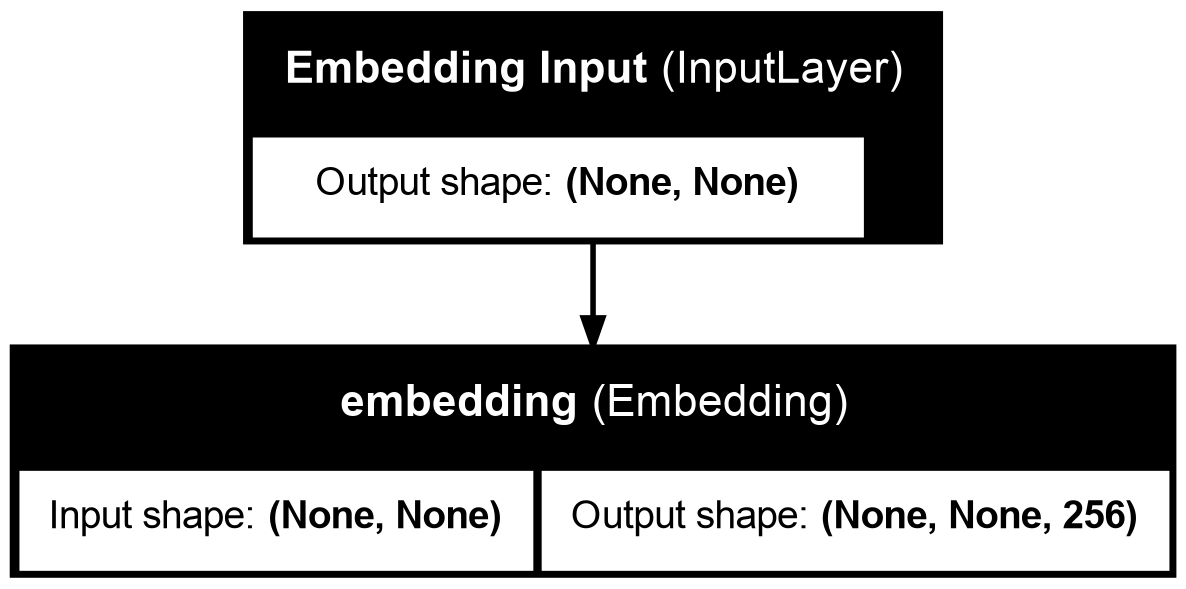

In [18]:
keras.utils.plot_model(
    embedding_model, 
    show_layer_names=True,
    show_shapes=True
)

In [ ]:
# preparing input data
X = np.array([
    sentence_to_tokens(sentence)
    for sentence in df.text
])
X

In [13]:
embedding_model.compile(
    optimizer = 'adam',
    loss = {
        embedding_model_output.name : keras.losses.CategoricalCrossentropy()
    },
    loss_weights = {
        embedding_model_output.name : 1.0
    }
)